In [1]:
%pip install opendatasets pandas numpy sklearn jovian --quiet

Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [2]:
import opendatasets as od
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib

import os
%matplotlib inline

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 150)
sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['figure.facecolor'] = '#00000000'

In [3]:
os.environ["KAGGLE_USERNAME"] = "vathanateng"
os.environ["KAGGLE_KEY"] = "5acb6299461a7ab5bc016e78f8890fe4"

In [4]:
import pandas as pd

In [5]:
raw_df = pd.read_csv('weatherAUS.csv')

In [6]:
raw_df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.000000,144199.000000,142199.000000,82670.000000,75625.000000,135197.000000,143693.000000,142398.000000,142806.000000,140953.000000,130395.00000,130432.000000,89572.000000,86102.000000,143693.000000,141851.00000
mean,12.194034,23.221348,2.360918,5.468232,7.611178,40.035230,14.043426,18.662657,68.880831,51.539116,1017.64994,1015.255889,4.447461,4.509930,16.990631,21.68339
std,6.398495,7.119049,8.478060,4.193704,3.785483,13.607062,8.915375,8.809800,19.029164,20.795902,7.10653,7.037414,2.887159,2.720357,6.488753,6.93665
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.50000,977.100000,0.000000,0.000000,-7.200000,-5.40000
25%,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.90000,1010.400000,1.000000,2.000000,12.300000,16.60000
50%,12.000000,22.600000,0.000000,4.800000,8.400000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.60000,1015.200000,5.000000,5.000000,16.700000,21.10000
75%,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.40000,1020.000000,7.000000,7.000000,21.600000,26.40000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.00000,1039.600000,9.000000,9.000000,40.200000,46.70000


In [7]:
raw_df.dropna(subset=['RainTomorrow'], inplace=True)

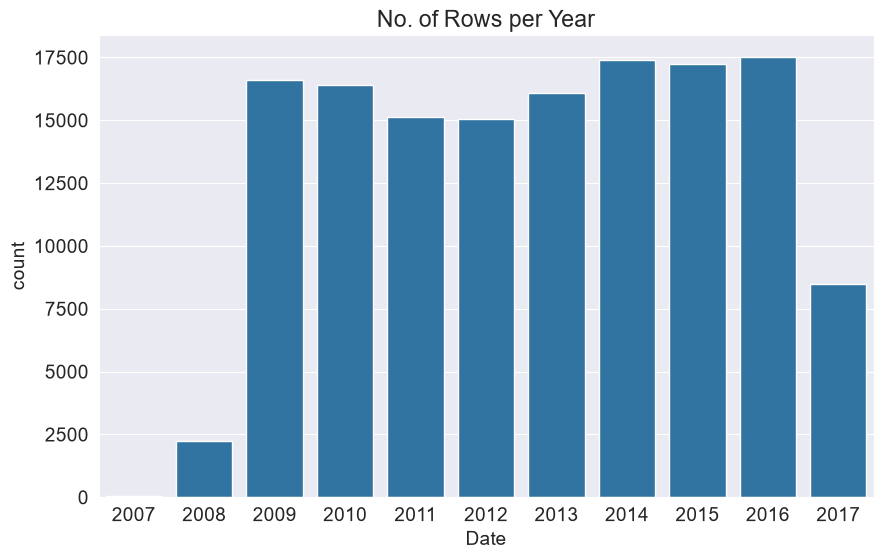

In [8]:
plt.title('No. of Rows per Year')
sns.countplot(x=pd.to_datetime(raw_df.Date).dt.year);

In [9]:
year = pd.to_datetime(raw_df.Date).dt.year
train_df = raw_df[year < 2015]
val_df = raw_df[year == 2015]
test_df = raw_df[year > 2015]

In [10]:
print('train_df.shape : ', train_df.shape)
print('val_df.shape : ', val_df.shape)
print('test_df.shape : ', test_df.shape);

train_df.shape :  (98988, 23)
val_df.shape :  (17231, 23)
test_df.shape :  (25974, 23)


In [11]:
input_cols = list(train_df.columns)[1:-1]
target_col = 'RainTomorrow'

In [12]:
train_inputs = train_df[input_cols].copy()  
train_targets = train_df[target_col].copy()

In [13]:
val_inputs = val_df[input_cols].copy()
val_targets = val_df[target_col].copy()

In [14]:
test_inputs = test_df[input_cols].copy()
test_targets = test_df[target_col].copy()

In [15]:
raw_df.loc[raw_df['MinTemp'] < 40, ['MinTemp']]

,MinTemp
0,13.4
1,7.4
2,12.9
3,9.2
4,17.5
...,...
145454,3.5
145455,2.8
145456,3.6
145457,5.4


In [16]:
numeric_cols = train_inputs.select_dtypes(include=np.number).columns.tolist()
categorical_cols = train_inputs.select_dtypes('object').columns.tolist()
# split the numeric and catagories columns into two differen dataframes 


C:\Users\User\AppData\Local\Temp\ipykernel_5340\996519459.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_inputs.select_dtypes('object').columns.tolist()


In [17]:
print(numeric_cols)

['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']


In [18]:
print(categorical_cols)

['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']


In [19]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler().fit(raw_df[numeric_cols]) # give a change from 0-1 (normalization) to the numeric columns in the dataset. this is just set up, we will use the fitted scaler to transform the numeric columns in the train_inputs, val_inputs, and test_inputs dataframes.
train_inputs[numeric_cols] = scaler.transform(train_inputs[numeric_cols]) # time to transform the numeric columns in the train_inputs dataframe using the fitted scaler.
val_inputs[numeric_cols] = scaler.transform(val_inputs[numeric_cols])
test_inputs[numeric_cols] = scaler.transform(test_inputs[numeric_cols])


In [20]:
val_inputs.describe().loc[['min', 'max']]

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
min,0.007075,0.030246,0.000000,0.000000,0.0,0.007752,0.000000,0.000000,0.04,0.0,0.125620,0.0816,0.000000,0.000000,0.021097,0.026871
max,0.952830,0.948960,0.666307,0.485517,1.0,1.000000,0.669231,0.850575,1.00,1.0,0.971901,0.9632,0.888889,0.888889,0.943038,0.925144


In [21]:
#encoding Categorical data 
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(raw_df[categorical_cols])
#'fit'learns the categories from your data 
encoded_cols = list(encoder.get_feature_names_out(categorical_cols))
#some columns change to multiple columns generated by 'get_feature_names_out' : Example → ['color_red', 'color_blue', 'color_green', 'city_NYC', 'city_LA', 'gender_M', 'gender_F']
train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols])
val_inputs[encoded_cols] = encoder.transform(val_inputs[categorical_cols])
test_inputs[encoded_cols] = encoder.transform(test_inputs[categorical_cols])

C:\Users\User\AppData\Local\Temp\ipykernel_5340\3793360620.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols])
C:\Users\User\AppData\Local\Temp\ipykernel_5340\3793360620.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols])
C:\Users\User\AppData\Local\Temp\ipykernel_5340\3793360620.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of callin

In [22]:
test_inputs 

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,Location_Adelaide,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera,WindGustDir_E,WindGustDir_ENE,WindGustDir_ESE,WindGustDir_N,WindGustDir_NE,WindGustDir_NNE,WindGustDir_NNW,WindGustDir_NW,WindGustDir_S,WindGustDir_SE,WindGustDir_SSE,WindGustDir_SSW,WindGustDir_SW,WindGustDir_W,WindGustDir_WNW,WindGustDir_WSW,WindGustDir_nan,WindDir9am_E,WindDir9am_ENE,WindDir9am_ESE,WindDir9am_N,WindDir9am_NE,WindDir9am_NNE,WindDir9am_NNW,WindDir9am_NW,WindDir9am_S,WindDir9am_SE,WindDir9am_SSE,WindDir9am_SSW,WindDir9am_SW,WindDir9am_W,WindDir9am_WNW,WindDir9am_WSW,WindDir9am_nan,WindDir3pm_E,WindDir3pm_ENE,WindDir3pm_ESE,WindDir3pm_N,WindDir3pm_NE,WindDir3pm_NNE,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,WindDir3pm_nan,RainToday_No,RainToday_Yes,RainToday_nan
2498,Albury,0.681604,0.801512,0.000000,NaN,NaN,ENE,0.372093,NaN,ESE,0.000000,0.080460,0.46,0.17,0.543802,0.5136,0.777778,0.333333,0.702532,0.808061,No,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2499,Albury,0.693396,0.725898,0.001078,NaN,NaN,SSE,0.341085,SSE,SE,0.069231,0.195402,0.54,0.30,0.505785,0.5008,0.888889,0.888889,0.675105,0.712092,No,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2500,Albury,0.634434,0.527410,0.005930,NaN,NaN,ENE,0.325581,ESE,ENE,0.084615,0.448276,0.62,0.67,0.553719,0.6032,0.888889,0.888889,0.611814,0.477927,Yes,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2501,Albury,0.608491,0.538752,0.042049,NaN,NaN,SSE,0.255814,SE,SSE,0.069231,0.195402,0.74,0.65,0.618182,0.6304,0.888889,0.888889,0.556962,0.518234,Yes,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1

In [23]:
#now we combine numeric and encoded categorical columns into a single dataframe for each of train, validation, and test sets.

In [24]:
X_train = train_inputs[numeric_cols + encoded_cols]
X_val = val_inputs[numeric_cols + encoded_cols]
X_test = test_inputs[numeric_cols + encoded_cols]

In [25]:
X_train 

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,Location_Adelaide,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera,WindGustDir_E,WindGustDir_ENE,WindGustDir_ESE,WindGustDir_N,WindGustDir_NE,WindGustDir_NNE,WindGustDir_NNW,WindGustDir_NW,WindGustDir_S,WindGustDir_SE,WindGustDir_SSE,WindGustDir_SSW,WindGustDir_SW,WindGustDir_W,WindGustDir_WNW,WindGustDir_WSW,WindGustDir_nan,WindDir9am_E,WindDir9am_ENE,WindDir9am_ESE,WindDir9am_N,WindDir9am_NE,WindDir9am_NNE,WindDir9am_NNW,WindDir9am_NW,WindDir9am_S,WindDir9am_SE,WindDir9am_SSE,WindDir9am_SSW,WindDir9am_SW,WindDir9am_W,WindDir9am_WNW,WindDir9am_WSW,WindDir9am_nan,WindDir3pm_E,WindDir3pm_ENE,WindDir3pm_ESE,WindDir3pm_N,WindDir3pm_NE,WindDir3pm_NNE,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,WindDir3pm_nan,RainToday_No,RainToday_Yes,RainToday_nan
0,0.516509,0.523629,0.001617,NaN,NaN,0.294574,0.153846,0.275862,0.71,0.22,0.449587,0.4800,0.888889,NaN,0.508439,0.522073,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,0.375000,0.565217,0.000000,NaN,NaN,0.294574,0.030769,0.252874,0.44,0.25,0.497521,0.4912,NaN,NaN,0.514768,0.570058,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,0.504717,0.576560,0.000000,NaN,NaN,0.310078,0.146154,0.298851,0.38,0.30,0.447934,0.5056,NaN,0.222222,0.594937,0.548944,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0.417453,0.620038,0.000000,NaN,NaN,0.139535,0.084615,0.103448,0.45,0.16,0.613223,0.5712,NaN,NaN,0.533755,0.612284,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.6132

In [26]:
from sklearn import set_config
set_config(display='text')

In [27]:
#Training and Visualizing Decision Trees
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth = 5, random_state=42) 
#max_depth : how deep the tree can go. if we don't set this, the tree will keep growing until it perfectly fits the training data, which is not good for generalization. it gonna become overfitting. so we set a limit to the depth of the tree.
#random_state : to make sure that the results are reproducible. if we don't set this, the results will be different every time we run the code., the number can be anything. (0,1,2,3,4,5,6,7,8,9) it doesn't matter. we just need to set it to a fixed number so that the results are reproducible.


In [28]:
model.fit(X_train, train_targets)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [29]:
from sklearn.metrics import accuracy_score, confusion_matrix 
train_predict = model.predict(X_train) 
#by the time we calling predict method, 
train_predict

array(['No', 'No', 'No', ..., 'No', 'No', 'No'],
      shape=(98988,), dtype=object)

In [30]:
pd.Series(train_predict).value_counts()

No     87528
Yes    11460
Name: count, dtype: int64

In [31]:
train_probs = model.predict_proba(X_train)

In [32]:
train_probs
# instead of yes or no , it give you the probability of each class for each sample in the training set. The output is a 2D array where each row corresponds to a sample and each column corresponds to a class. The values in each row sum up to 1, representing the predicted probabilities for each class.

array([[0.96673589, 0.03326411],
       [0.96673589, 0.03326411],
       [0.96673589, 0.03326411],
       ...,
       [0.96673589, 0.03326411],
       [0.96673589, 0.03326411],
       [0.80009787, 0.19990213]], shape=(98988, 2))

In [33]:
#check accuracy of the model on the training set
accuracy_score( train_predict, train_targets)
#84% accuracy on the training set is good, but we need to check the accuracy on the validation set to see if the model is overfitting or not.
#accuracy=total number of predictions/number of correct predictions​

0.8400715238210692

In [34]:
model.score(X_val, val_targets)
#this line means that we are checking the accuracy of the model on the validation set. The score method returns the mean accuracy on the given test data and labels. In this case, it will return the accuracy of the model on the validation set (X_val, val_targets).
#1.Runs model.predict(X_val) — generates predictions on the validation set
#2.Compares those predictions to val_targets using the same accuracy formula

0.8388950147989089

In [35]:
val_targets.value_counts() / len(val_targets)

RainTomorrow
No     0.788289
Yes    0.211711
Name: count, dtype: float64

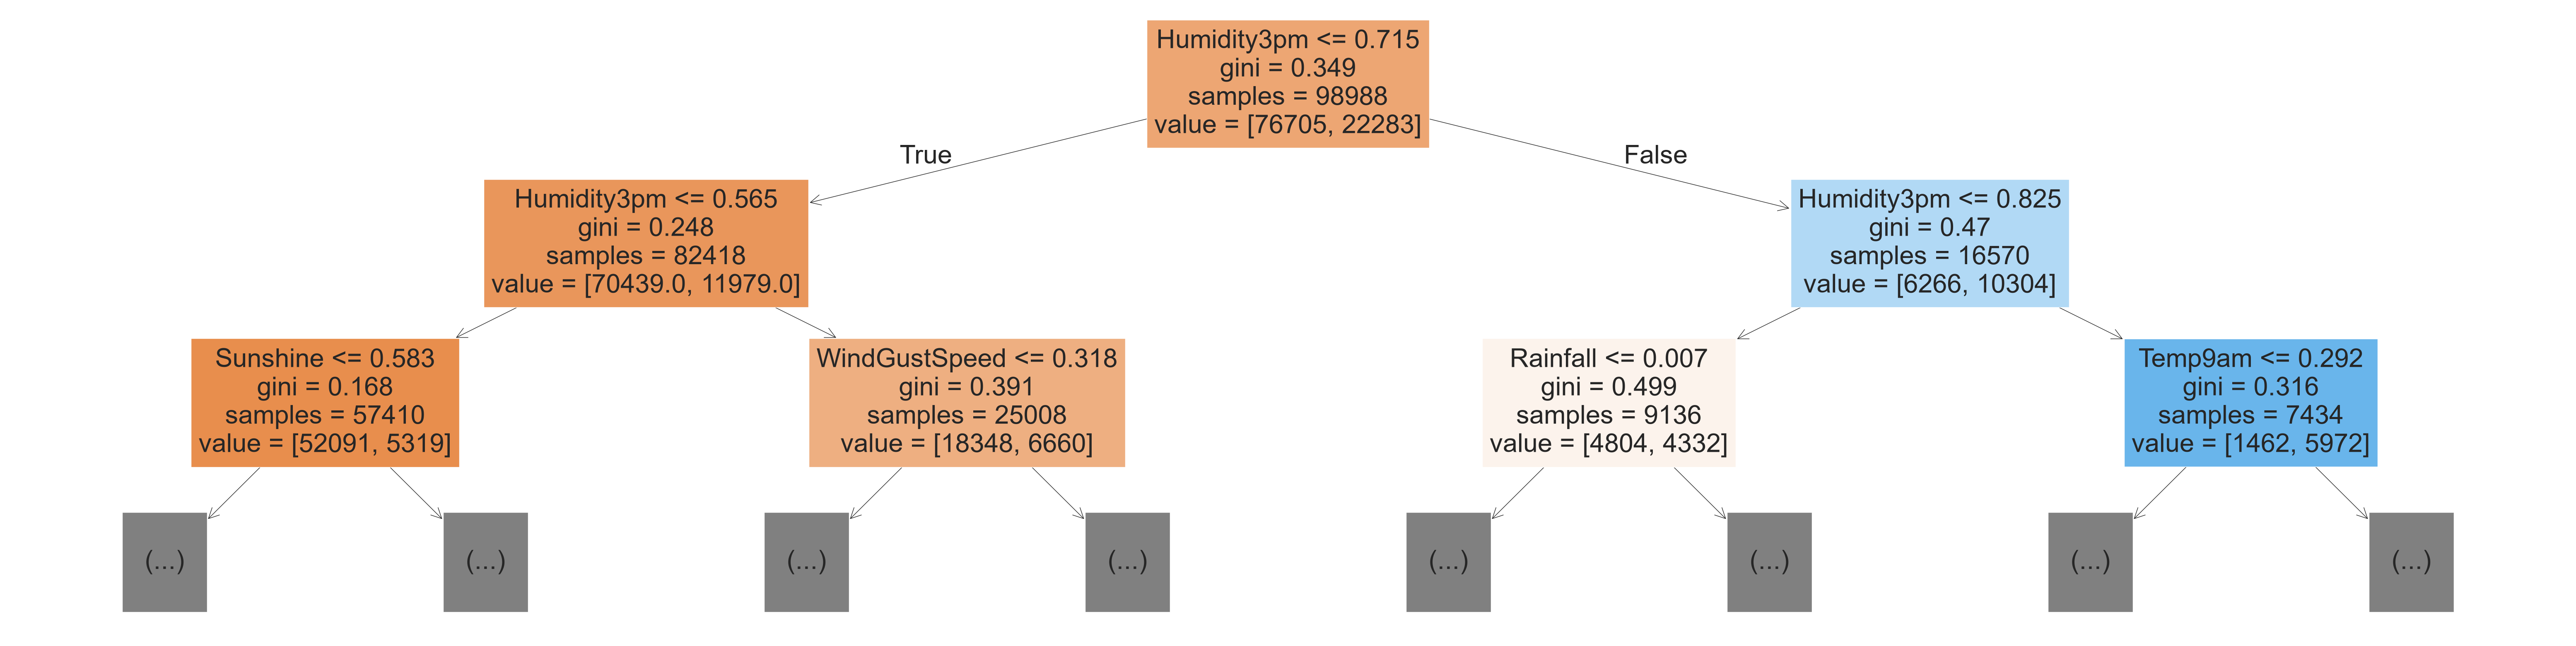

In [36]:
from sklearn.tree import plot_tree, export_text
plt.figure(figsize=(80,20))
plot_tree(model, feature_names=X_train.columns, max_depth=2, filled=True);

In [37]:
model.tree_.max_depth
#check depth of the tree

5

In [38]:
tree_text = export_text(model, feature_names = list(X_train.columns))
print(tree_text)
# This will print the text representation of the decision tree, showing the conditions at each node and the predicted class at each leaf. The depth of the tree can be seen in the number of levels in the printed output. 

|--- Humidity3pm <= 0.72
|   |--- Humidity3pm <= 0.56
|   |   |--- Sunshine <= 0.58
|   |   |   |--- Pressure3pm <= 0.58
|   |   |   |   |--- WindGustSpeed <= 0.36
|   |   |   |   |   |--- class: No
|   |   |   |   |--- WindGustSpeed >  0.36
|   |   |   |   |   |--- class: No
|   |   |   |--- Pressure3pm >  0.58
|   |   |   |   |--- WindGustSpeed <= 0.32
|   |   |   |   |   |--- class: No
|   |   |   |   |--- WindGustSpeed >  0.32
|   |   |   |   |   |--- class: No
|   |   |--- Sunshine >  0.58
|   |   |   |--- WindGustSpeed <= 0.36
|   |   |   |   |--- Humidity3pm <= 0.44
|   |   |   |   |   |--- class: No
|   |   |   |   |--- Humidity3pm >  0.44
|   |   |   |   |   |--- class: No
|   |   |   |--- WindGustSpeed >  0.36
|   |   |   |   |--- Sunshine <= 0.73
|   |   |   |   |   |--- class: No
|   |   |   |   |--- Sunshine >  0.73
|   |   |   |   |   |--- class: No
|   |--- Humidity3pm >  0.56
|   |   |--- WindGustSpeed <= 0.32
|   |   |   |--- Rainfall <= 0.01
|   |   |   |   |--- Press

In [39]:
model.feature_importances_
# importance(f)= ∑​(nodes using f)×(total samples/samples at node​)×Δimpurity
#feature_importances_ attribute of the trained DecisionTreeClassifier model returns an array of shape (n_features,) where each element represents the importance of the corresponding feature in making predictions. The importance of a feature is calculated based on how much it contributes to reducing impurity (e.g., Gini impurity or entropy) in the decision tree. A higher value indicates that the feature is more important for making accurate predictions.

array([0.00000000e+00, 1.45078873e-04, 6.19282790e-02, 1.69790166e-03,
       4.45456707e-02, 7.94509552e-02, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 7.37509657e-01, 0.00000000e+00, 6.08866044e-02,
       0.00000000e+00, 3.16820329e-03, 1.06676497e-02, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

In [40]:
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending = False)

In [41]:
importance_df.head(10)

,feature,importance
9,Humidity3pm,0.737510
5,WindGustSpeed,0.079451
2,Rainfall,0.061928
11,Pressure3pm,0.060887
4,Sunshine,0.044546
14,Temp9am,0.010668
13,Cloud3pm,0.003168
3,Evaporation,0.001698
1,MaxTemp,0.000145
6,WindSpeed9am,0.000000


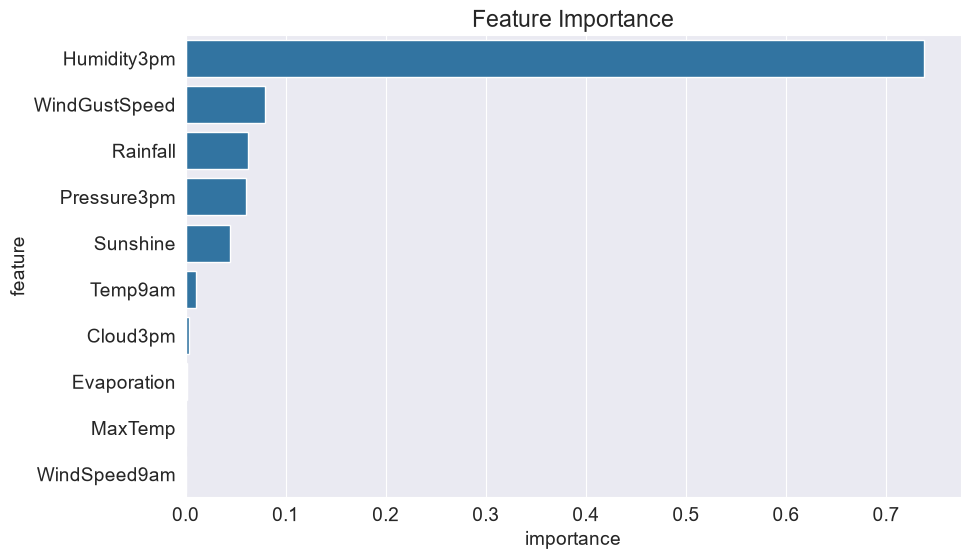

In [42]:
plt.title('Feature Importance')
sns.barplot(data=importance_df.head(10), x = 'importance', y = 'feature');

In [43]:
#hyperparameter is a parameter whose value is set before the learning process begins. In the context of machine learning, hyperparameters are used to control the training process and the structure of the model. Examples of hyperparameters include learning rate, number of trees in a random forest, depth of a decision tree, and regularization parameters. Hyperparameter tuning involves selecting the best combination of hyperparameters to optimize model performance on validation data. 

In [44]:
model.fit(X_train, train_targets)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [45]:
model.score(X_train, train_targets)

0.8400715238210692

In [46]:
model.score(X_val, val_targets)

0.8388950147989089

In [47]:
model.classes_

array(['No', 'Yes'], dtype=object)

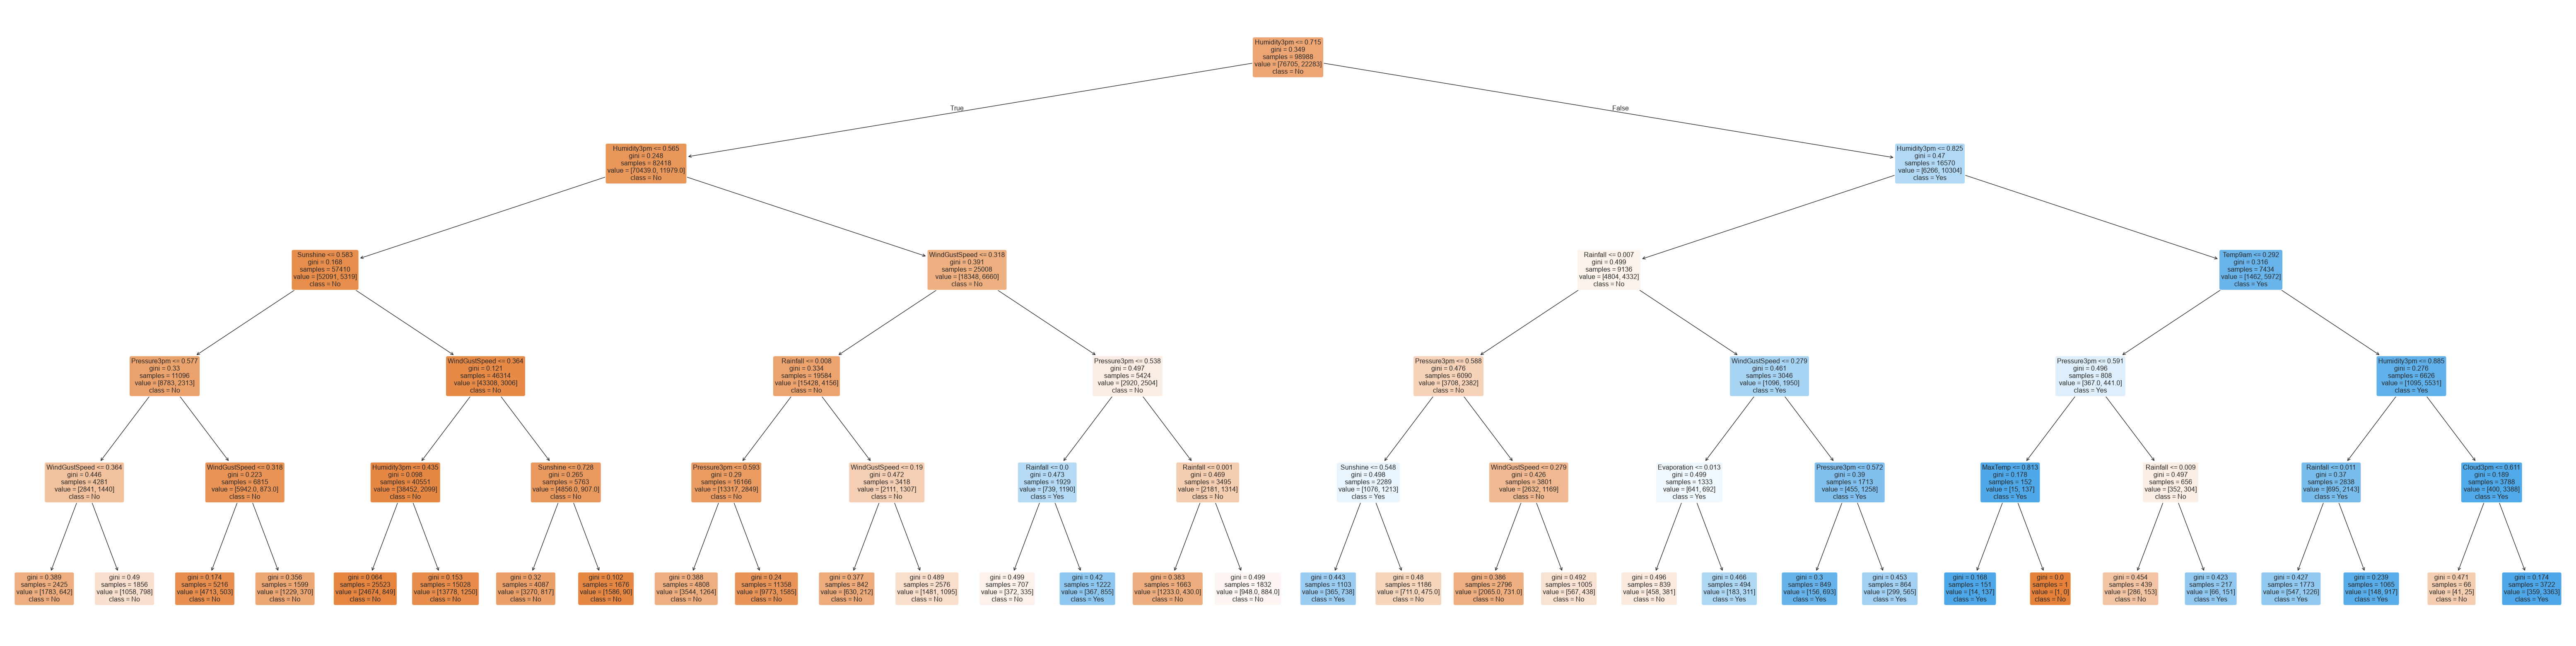

In [48]:
plt.figure(figsize=(80,20))
plot_tree(model, feature_names=X_train.columns, filled=True, rounded=True, class_names=model.classes_);

In [49]:
print(export_text(model, feature_names=list(X_train.columns)))

|--- Humidity3pm <= 0.72
|   |--- Humidity3pm <= 0.56
|   |   |--- Sunshine <= 0.58
|   |   |   |--- Pressure3pm <= 0.58
|   |   |   |   |--- WindGustSpeed <= 0.36
|   |   |   |   |   |--- class: No
|   |   |   |   |--- WindGustSpeed >  0.36
|   |   |   |   |   |--- class: No
|   |   |   |--- Pressure3pm >  0.58
|   |   |   |   |--- WindGustSpeed <= 0.32
|   |   |   |   |   |--- class: No
|   |   |   |   |--- WindGustSpeed >  0.32
|   |   |   |   |   |--- class: No
|   |   |--- Sunshine >  0.58
|   |   |   |--- WindGustSpeed <= 0.36
|   |   |   |   |--- Humidity3pm <= 0.44
|   |   |   |   |   |--- class: No
|   |   |   |   |--- Humidity3pm >  0.44
|   |   |   |   |   |--- class: No
|   |   |   |--- WindGustSpeed >  0.36
|   |   |   |   |--- Sunshine <= 0.73
|   |   |   |   |   |--- class: No
|   |   |   |   |--- Sunshine >  0.73
|   |   |   |   |   |--- class: No
|   |--- Humidity3pm >  0.56
|   |   |--- WindGustSpeed <= 0.32
|   |   |   |--- Rainfall <= 0.01
|   |   |   |   |--- Press

In [50]:
def max_depth_error(md):
    model = DecisionTreeClassifier(max_depth=md, random_state=42)
    model.fit(X_train, train_targets)
    train_acc = 1- model.score(X_train, train_targets)
    val_acc = 1- model.score(X_val, val_targets)
    return {'Max_depth' : md, 'Train Error' : train_acc, 'validation Error' : val_acc}
  
  

In [51]:
errors_df = pd.DataFrame([max_depth_error(md) for md in range(1, 21)])
#pd.dataframe() is a function in the pandas library that is used to create a DataFrame object. A DataFrame is a two -dimensional, size-mutable, and heterogeneous tabular data structure with labeled axes (rows and columns). It is similar to a spreadsheet or SQL table, and it is one of the most commonly used data structures
#it convert the list of dictionaries returned by the max_depth_error function into a DataFrame, where each dictionary represents a row in the DataFrame and the keys of the dictionaries become the column names.

In [52]:
errors_df

,Max_depth,Train Error,validation Error
0,1,0.184315,0.177935
1,2,0.179547,0.172712
2,3,0.170920,0.166734
3,4,0.164495,0.163078
4,5,0.159928,0.161105
5,6,0.154877,0.154721
6,7,0.151877,0.155069
7,8,0.146775,0.153154
8,9,0.140158,0.154721
9,10,0.132390,0.155360


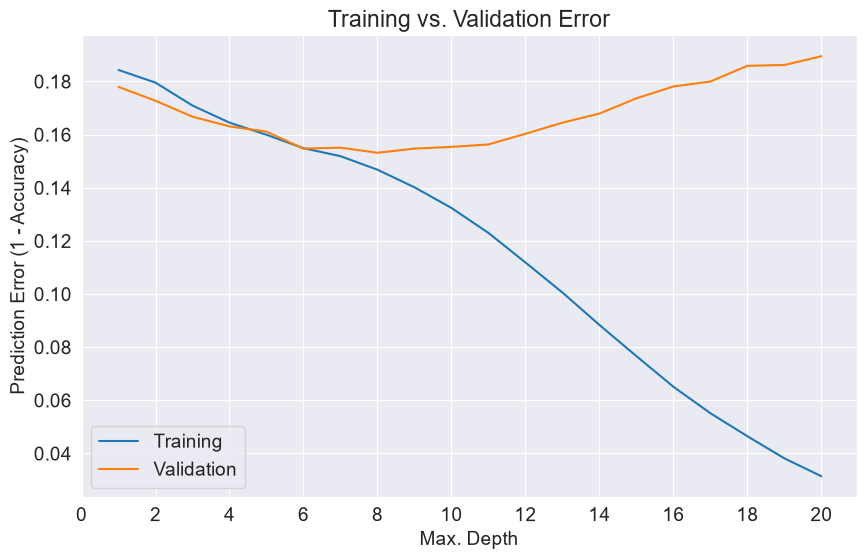

In [53]:
plt.figure()
plt.plot(errors_df['Max_depth'], errors_df['Train Error'])
plt.plot(errors_df['Max_depth'], errors_df['validation Error'])
plt.title('Training vs. Validation Error')
plt.xticks(range(0,21, 2))
plt.xlabel('Max. Depth')
plt.ylabel('Prediction Error (1 - Accuracy)')
plt.legend(['Training', 'Validation'])

In [54]:
model = DecisionTreeClassifier(max_leaf_nodes=128, random_state=42)

In [55]:
model.fit(X_train, train_targets)

DecisionTreeClassifier(max_leaf_nodes=128, random_state=42)

In [56]:
model.score(X_train, train_targets)

0.8495878288277366

In [57]:
model.score(X_val, val_targets)

0.8446404735650862

In [58]:
model.tree_.max_depth

11

In [59]:
model_text = export_text(model, feature_names=list(X_train.columns))
print(model_text[:3000])

|--- Humidity3pm <= 0.72
|   |--- Humidity3pm <= 0.56
|   |   |--- Sunshine <= 0.58
|   |   |   |--- Pressure3pm <= 0.58
|   |   |   |   |--- WindGustSpeed <= 0.36
|   |   |   |   |   |--- Humidity3pm <= 0.28
|   |   |   |   |   |   |--- class: No
|   |   |   |   |   |--- Humidity3pm >  0.28
|   |   |   |   |   |   |--- WindDir3pm_N <= 0.50
|   |   |   |   |   |   |   |--- Sunshine <= 0.37
|   |   |   |   |   |   |   |   |--- Pressure3pm <= 0.44
|   |   |   |   |   |   |   |   |   |--- class: Yes
|   |   |   |   |   |   |   |   |--- Pressure3pm >  0.44
|   |   |   |   |   |   |   |   |   |--- WindDir3pm_NNW <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- class: No
|   |   |   |   |   |   |   |   |   |--- WindDir3pm_NNW >  0.50
|   |   |   |   |   |   |   |   |   |   |--- class: Yes
|   |   |   |   |   |   |   |--- Sunshine >  0.37
|   |   |   |   |   |   |   |   |--- class: No
|   |   |   |   |   |   |--- WindDir3pm_N >  0.50
|   |   |   |   |   |   |   |--- class: No
|   |   |   

In [60]:
# now we combine dept and leaf nodes to see if we can get better results.
model = DecisionTreeClassifier(max_depth=5, max_leaf_nodes=128, random_state=42)
model.fit(X_train, train_targets)
model.score(X_train, train_targets)


0.8400715238210692

In [61]:
model.score(X_val, val_targets)

0.8388950147989089

In [62]:
#testing random forest classifier
from sklearn.ensemble import RandomForestClassifier

In [63]:
model = RandomForestClassifier(n_jobs=-1, random_state=42)
#random forest is an ensemble learning method that combines multiple decision trees to improve predictive performance and reduce overfitting. It works by training a collection of decision trees on different subsets of the training data and features, and then aggregating their predictions (e.g., by majority voting for classification or averageing for regrression). 
# The "n_jobs=-1" parameter allows the model to use all available CPU cores for parallel processing, which can speed up training. 
# The "random_state = 42" parameter ensures that the results are reproducible. If we don't set this, the results will be different every time we run the code. The number can be anything (0,1,2,3,4,5,6,7,8,9) it doesn't matter. We just need to set it to a fixed number so that the results are reproducible. 

In [64]:
model.fit(X_train, train_targets)


RandomForestClassifier(n_jobs=-1, random_state=42)

In [65]:
model.score(X_train, train_targets)


0.9999494888269285

In [66]:
model.score(X_val, val_targets)

0.8568858452788579

In [67]:
train_probs = model.predict_proba(X_train)
train_probs

array([[0.93, 0.07],
       [0.95, 0.05],
       [0.98, 0.02],
       ...,
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.96, 0.04]], shape=(98988, 2))

In [68]:
model.estimators_[0]
#model.estimators_ is an attribute of the RandomForestClassifier that returns a list of the individual decision tree classifiers that make up the random forest. Each element in the list is a DecisionTreeClassifier object, which can be accessed and analyzed individually. In this case, model.estimator[0] would give you the first decision tree in the random forest.

DecisionTreeClassifier(max_features='sqrt', random_state=1608637542)

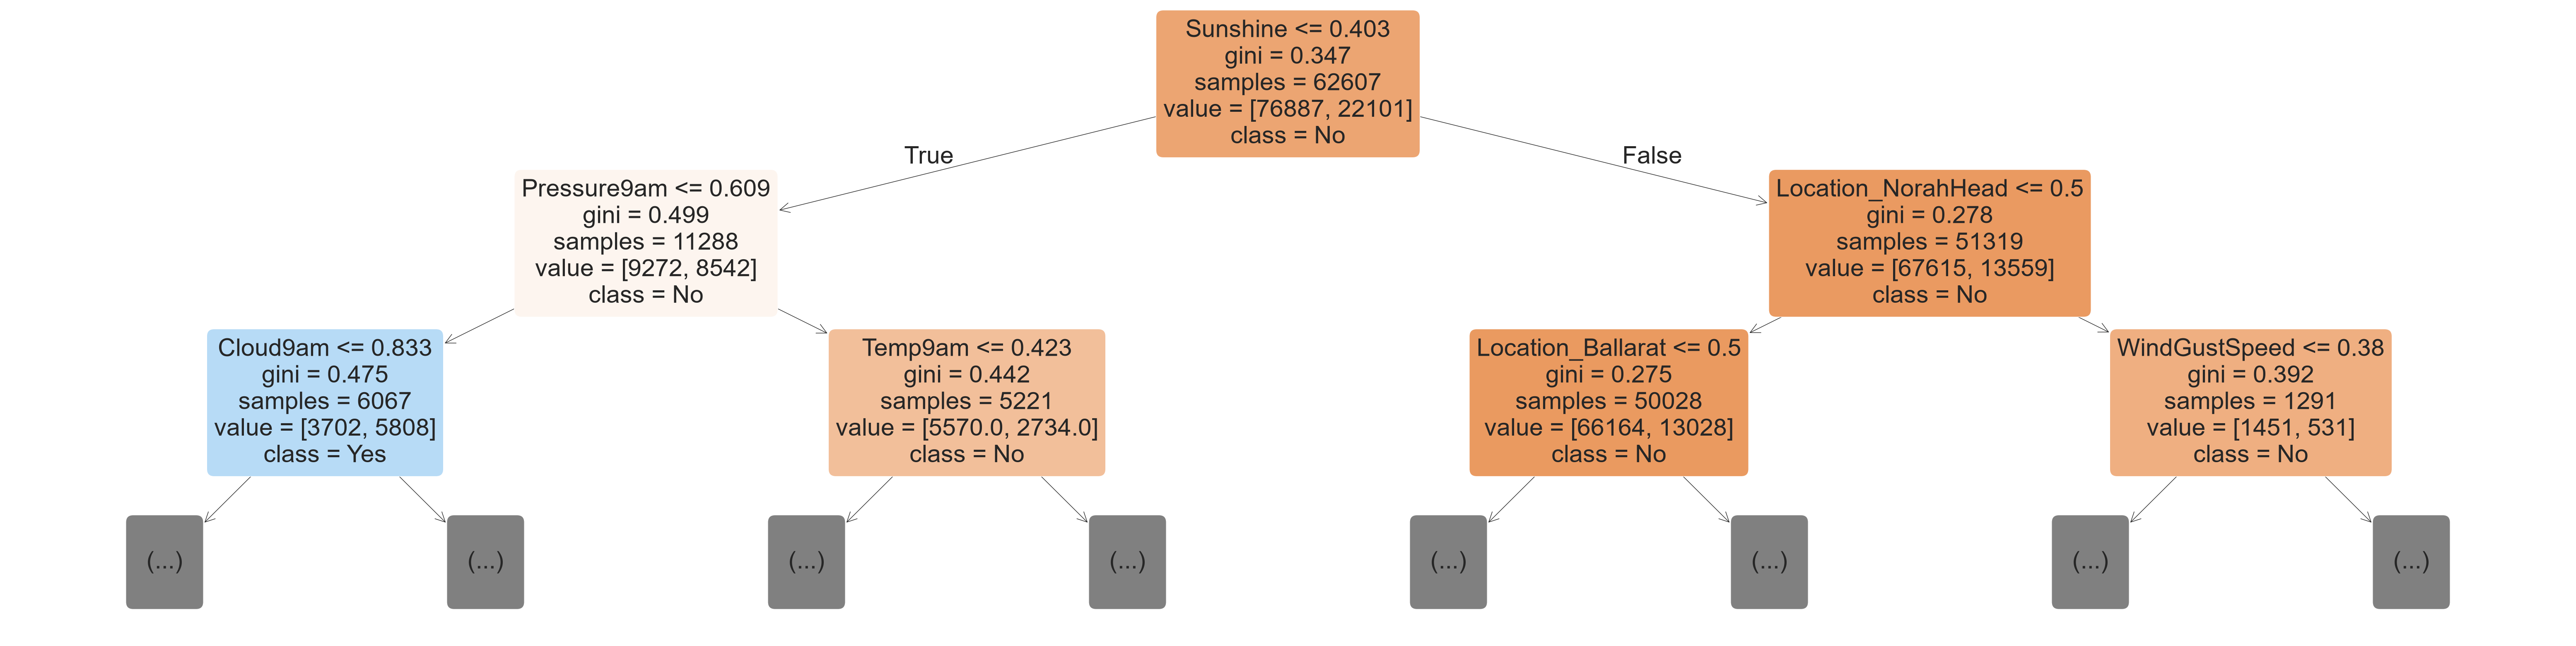

In [69]:
plt.figure(figsize=(80,20))
plot_tree(model.estimators_[0], max_depth=2, feature_names=X_train.columns, filled=True, rounded=True, class_names=model.classes_);

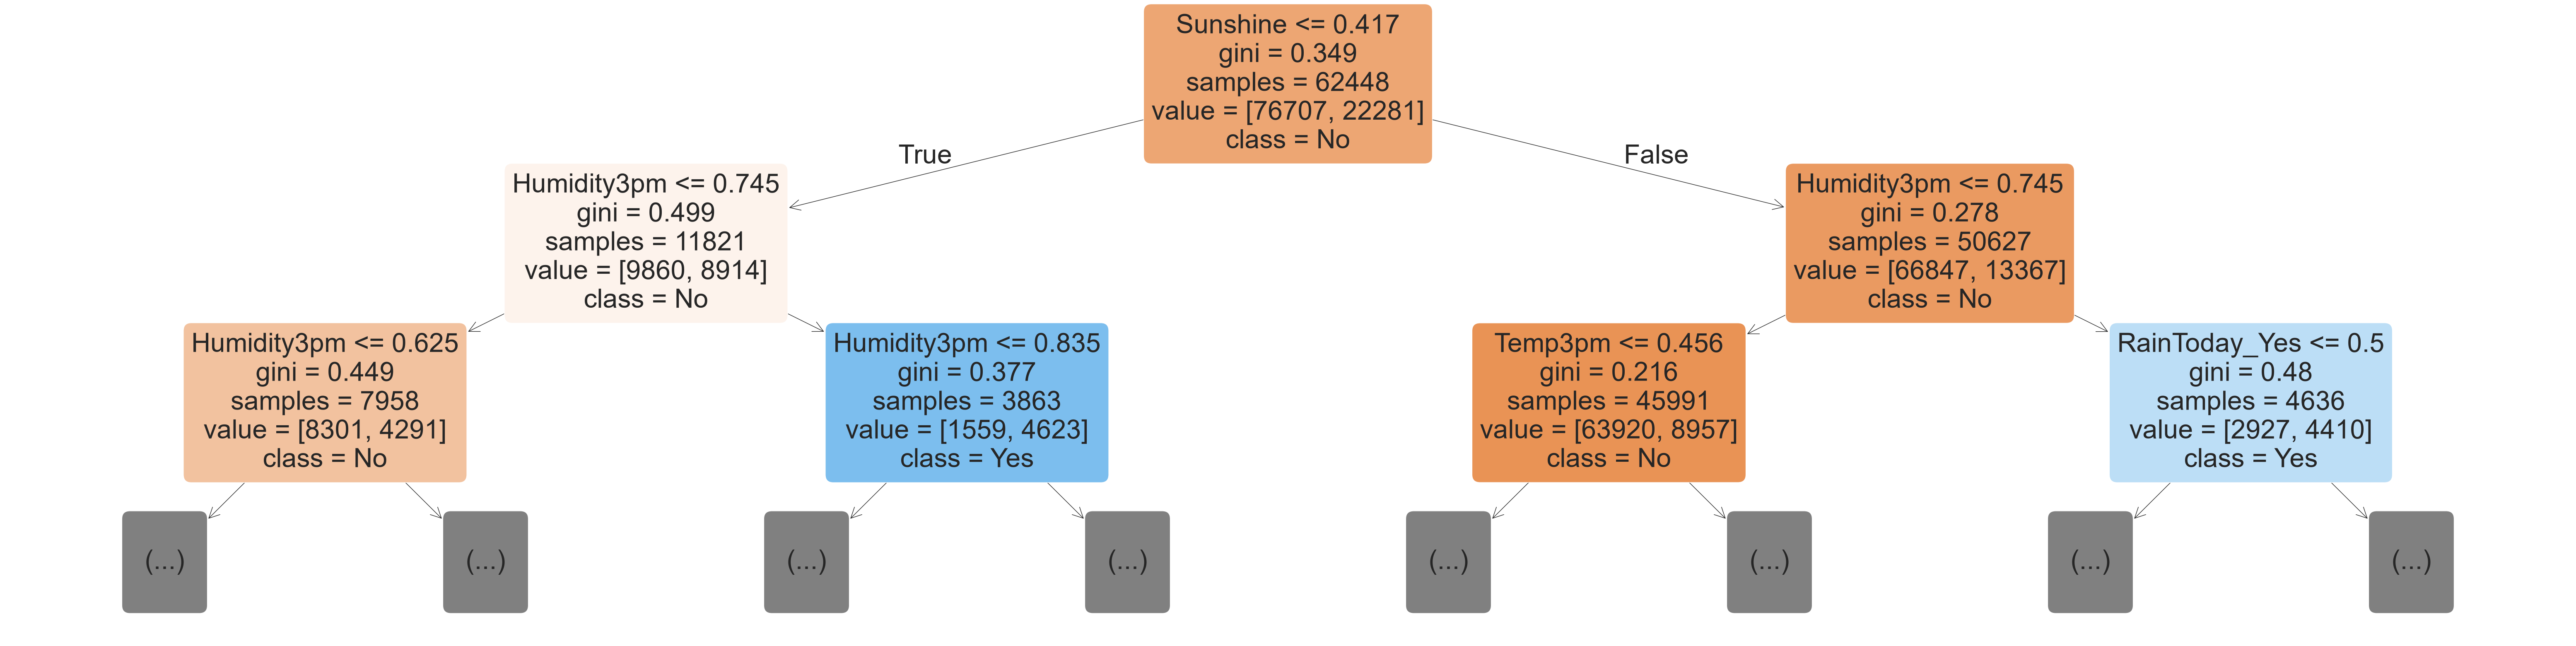

In [70]:
plt.figure(figsize=(80,20))
plot_tree(model.estimators_[15], max_depth=2, feature_names=X_train.columns, filled=True, rounded=True, class_names=model.classes_);

In [71]:
len(model.estimators_)

100

In [72]:
print(type(val_targets))
print(val_targets[:5])
print(model.classes_)
print(model.estimators_[0].classes_)

<class 'pandas.Series'>
2133    No
2134    No
2135    No
2136    No
2137    No
Name: RainTomorrow, dtype: str
['No' 'Yes']
[0. 1.]


In [73]:
print(model.classes_)
print(set(tree.classes_.tolist()[0] for tree in model.estimators_))  # just checking type/values

['No' 'Yes']
{0.0}


In [74]:
print(model.classes_)
print(model.estimators_[0].classes_)

['No' 'Yes']
[0. 1.]


In [75]:
# Random Forest Validation Accuracy
Forest_random = model.score(X_val, val_targets)
print('Random Forest Validation Accuracy : ', Forest_random)

# Map string labels to the same integer encoding the trees use internally
class_to_idx = {label: idx for idx, label in enumerate(model.classes_)}
val_targets_encoded = val_targets.map(class_to_idx)

#Find the best individual tree in the random forest based on validation accuracy


tree_accuracies = []
for i, tree in enumerate(model.estimators_):
    acc = tree.score(X_val,val_targets_encoded)  # Use encoded targets for scoring
    tree_accuracies.append(acc)
    
best_acc = max(tree_accuracies)
best_index = tree_accuracies.index(best_acc)
print(f'Best Individual Tree Validation Accuracy: {best_acc}')
print(f'Index of Best Tree: {best_index}')
print(f"Forest beats best individual tree: {Forest_random > best_acc}")
    #how enumerate works: it takes an iterable (like a list) and returns pairs of (index, value) for each item in the iterable. In this case, it is used to iterate over the individual decision trees in the random forest model. The variable 'i' will hold the index of the current tree (starting from 0), and 'tree' will hold the actual DecisionTreeClassifier object at that index. This allows us to access and evaluate each tree in the random forest one by one.
    #tree.score(X_val, val_targets) and model.estimators_[i].score(X_val, val_targets) it is the same thing. it is just a different way to access the individual decision trees in the random forest model. The score method returns the mean accuracy on the given test data and labels. In this case, it will return the accuracy of the individual decision tree on the validation set (X_val, val_targets). 
    

Random Forest Validation Accuracy :  0.8568858452788579


d:\MachineLearningProjectPractice\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
d:\MachineLearningProjectPractice\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
d:\MachineLearningProjectPractice\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
d:\MachineLearningProjectPractice\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
d:\MachineLearningProjectPractice\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  

Best Individual Tree Validation Accuracy: 0.7915965411177529
Index of Best Tree: 85
Forest beats best individual tree: True


d:\MachineLearningProjectPractice\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
d:\MachineLearningProjectPractice\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
d:\MachineLearningProjectPractice\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


In [76]:
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)
# it is the importance of the whole random forest model. The feature_importances_ attribute of the RandomForestClassifier returns the importance of each feature in making predictions across all the decision trees in the random forest. It is calculated by averaging the importance scores of each feature across all the individual decision trees in the ensemble. A higher value indicates that the feature is more important for making accurate predictions in the random forest model.
#importance_df is a DataFrame that contains the feature names and their corresponding importance scores as determined by the Random Forest model. The DataFrame is sorted in descending order of importance, so the most important features appear at the top.

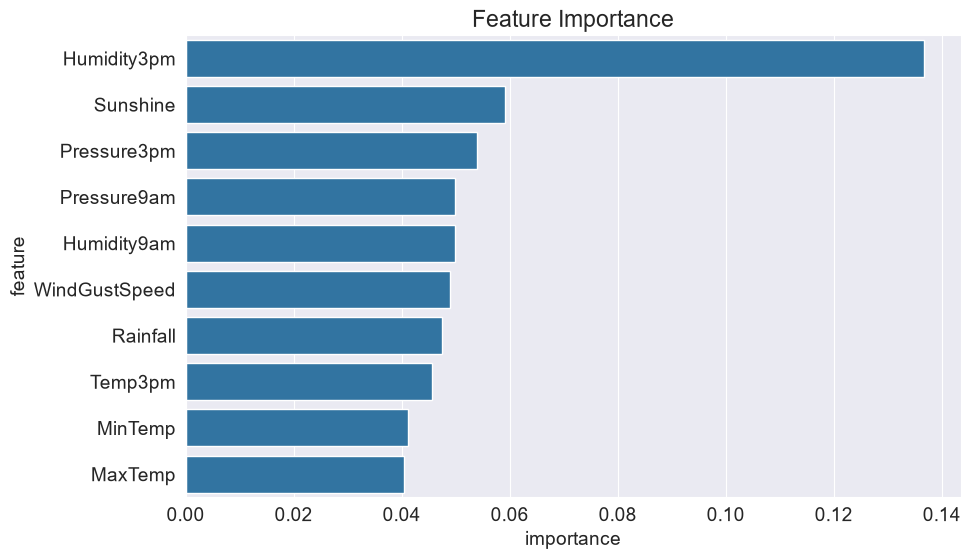

In [77]:
plt.title('Feature Importance')
sns.barplot(data=importance_df.head(10), x='importance', y='feature');

In [78]:
base_model = RandomForestClassifier(random_state=42, n_jobs=-1).fit(X_train, train_targets)
#base_model is a RandomForestClassifier that is trained on the training data (X_train, train_targets) with the specified random_state and n_jobs parameters. The random_state parameter ensures that the results are reproducible, while the n_jobs parameter allows the model to use all available CPU cores for parallel processing, which can speed up training. The base_model can be used as a baseline for comparison with other models or for further analysis.

In [79]:
base_train_acc = base_model.score(X_train, train_targets)
base_val_acc = base_model.score(X_val, val_targets)

In [80]:
base_accs = base_train_acc, base_val_acc
base_accs
#base_accs is a tuple that contains the training accuracy and validation accuracy of the base_model. The first element (base_train_acc) represents the accuracy of the model on the training set, while the second element (base_val_acc) represents the accuracy of the model on the validation set. This allows for a quick comparison of how well the model performs on both the training and validation data.

(0.9999494888269285, 0.8568858452788579)

In [81]:
# n_estimators is a hyperparameter of the RandomForestClassifier that specifies the number of decision trees to be built in the random forest. Each tree is trained on a random subset of the training data and features, and the final prediction is made by aggregating the predictions of all the individual trees (e.g., by majority voting for classification). A higher number of estimators can lead to better performance and more stable predictions, but it also increases computational cost and training time. The default value is usually 100, but it can be adjusted based on the specific problem and available resources.
#10 estimators
model = RandomForestClassifier(random_state=42, n_jobs=-1, n_estimators=10)
model.fit(X_train, train_targets)
acc_10 = model.score(X_train, train_targets), model.score(X_val, val_targets)
acc_10

(0.9874631268436578, 0.8466716963612094)

In [82]:
#500 estimators
model = RandomForestClassifier(random_state=42, n_jobs=-1, n_estimators=500)
model.fit(X_train, train_targets)
acc_500 = model.score(X_train, train_targets), model.score(X_val, val_targets)
acc_500

(0.9999797955307714, 0.8580465440194998)

In [83]:
model = RandomForestClassifier(random_state=42, n_jobs=-1)
model.fit(X_train, train_targets)
base_train_acc = model.score(X_train, train_targets)
base_val_acc = model.score(X_val, val_targets)


In [84]:
base_accs = base_train_acc, base_val_acc
base_accs

(0.9999494888269285, 0.8568858452788579)

In [85]:
#find the best max_features and n_estimators
max_train_acc = 0
max_val_acc = 0
best_mf = None
for mf in ['sqrt', 'log2', 0.5, 0.75, 1.0]:
  model = RandomForestClassifier(random_state=42, n_jobs=-1, max_features=mf)
  model.fit(X_train, train_targets)
  train_acc = model.score(X_train, train_targets)
  val_acc = model.score(X_val, val_targets)
  if(max_train_acc< train_acc and max_val_acc<val_acc ):
    max_train_acc = train_acc
    max_val_acc = val_acc
    best_mf = mf
print('Best max_features : ', best_mf)

n_estimators = [10, 50, 100, 200]
def test_params(max_features, n_estimators):
  max_train_acc = 0
  max_val_acc = 0
  best_estimator = None
  for n in n_estimators:
    model = RandomForestClassifier(random_state = 42, n_jobs = -1, max_features = max_features, n_estimators = n)
    model.fit(X_train, train_targets)
    train_acc = model.score(X_train, train_targets)
    val_acc = model.score(X_val, val_targets)
    if(train_acc > max_train_acc and val_acc > max_val_acc):
      max_train_acc = train_acc
      max_val_acc = val_acc
      best_estimator = n
  return max_train_acc, max_val_acc, best_estimator

test_params(best_mf, n_estimators)


Best max_features :  sqrt


(0.9999797955307714, 0.8573501247751146, 200)

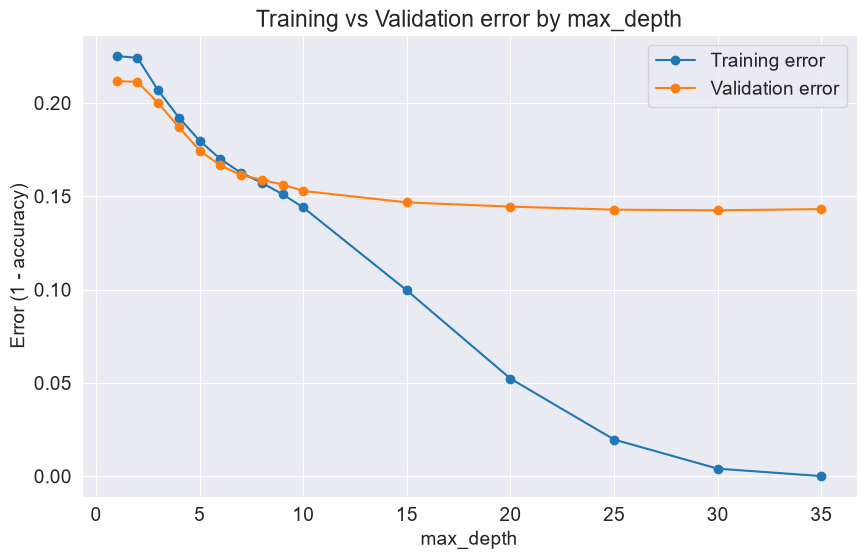

In [86]:
import matplotlib.pyplot as plt

max_depth_range = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 25, 30, None]  # None means no limit on depth
train_errors = []
val_errors = []

for depth in max_depth_range:
    model = RandomForestClassifier(random_state=42, n_jobs=-1, max_depth=depth)
    model.fit(X_train, train_targets)
    train_acc = model.score(X_train, train_targets)
    val_acc = model.score(X_val, val_targets)
    train_errors.append(1 - train_acc)
    val_errors.append(1 - val_acc)

# Replace None with a plottable number for the x-axis
x_labels = [d if d is not None else 35 for d in max_depth_range]

plt.figure(figsize=(10, 6))
plt.plot(x_labels, train_errors, 'o-', label='Training error')
plt.plot(x_labels, val_errors, 'o-', label='Validation error')
plt.xlabel('max_depth')
plt.ylabel('Error (1 - accuracy)')
plt.title('Training vs Validation error by max_depth')
plt.legend()
plt.grid(True)
plt.show()

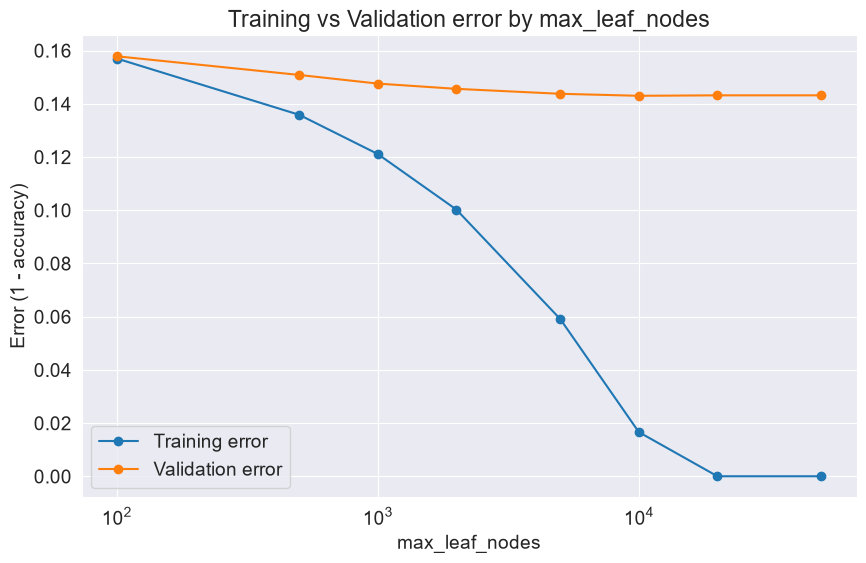

In [87]:
max_leaf_range = [100, 500, 1000, 2000, 5000, 10000, 20000, 50000]
train_errors_leaf = []
val_errors_leaf = []

for leaves in max_leaf_range:
    model = RandomForestClassifier(random_state=42, n_jobs=-1, max_leaf_nodes=leaves)
    model.fit(X_train, train_targets)
    train_acc = model.score(X_train, train_targets)
    val_acc = model.score(X_val, val_targets)
    train_errors_leaf.append(1 - train_acc)
    val_errors_leaf.append(1 - val_acc)

plt.figure(figsize=(10, 6))
plt.plot(max_leaf_range, train_errors_leaf, 'o-', label='Training error')
plt.plot(max_leaf_range, val_errors_leaf, 'o-', label='Validation error')
plt.xlabel('max_leaf_nodes')
plt.ylabel('Error (1 - accuracy)')
plt.title('Training vs Validation error by max_leaf_nodes')
plt.xscale('log')
plt.legend()
plt.grid(True)
plt.show()
#result so that a bit higher that 10000 and less that 20000 left nodes are good. 

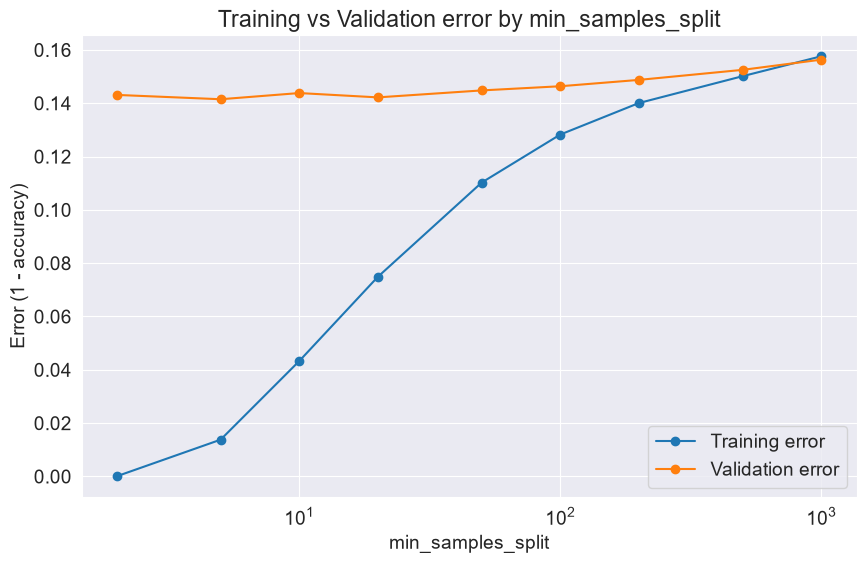

Optimal min_samples_split: 5


In [88]:
#
split_range = [2,5,10,20, 50 , 100, 200,500,1000]
train_errors_split = []
val_errors_split = []
for s in split_range : 
  model = RandomForestClassifier(random_state=42, n_jobs=-1, min_samples_split=s)
  model.fit(X_train, train_targets)
  train_acc = model.score(X_train, train_targets)
  val_acc = model.score(X_val, val_targets)
  train_errors_split.append(1 - train_acc)
  val_errors_split.append(1 - val_acc)
  
plt.figure(figsize=(10, 6))
plt.plot(split_range, train_errors_split, 'o-', label='Training error')
plt.plot(split_range, val_errors_split, 'o-', label='Validation error')
plt.xlabel('min_samples_split')
plt.ylabel('Error (1 - accuracy)')
plt.title('Training vs Validation error by min_samples_split')
plt.xscale('log')
plt.legend()
plt.grid(True)
plt.show()

best_split_idx = val_errors_split.index(min(val_errors_split))
print("Optimal min_samples_split:", split_range[best_split_idx])
# when it split around fewer than 2->5, the result is good, (train_error<val_error)

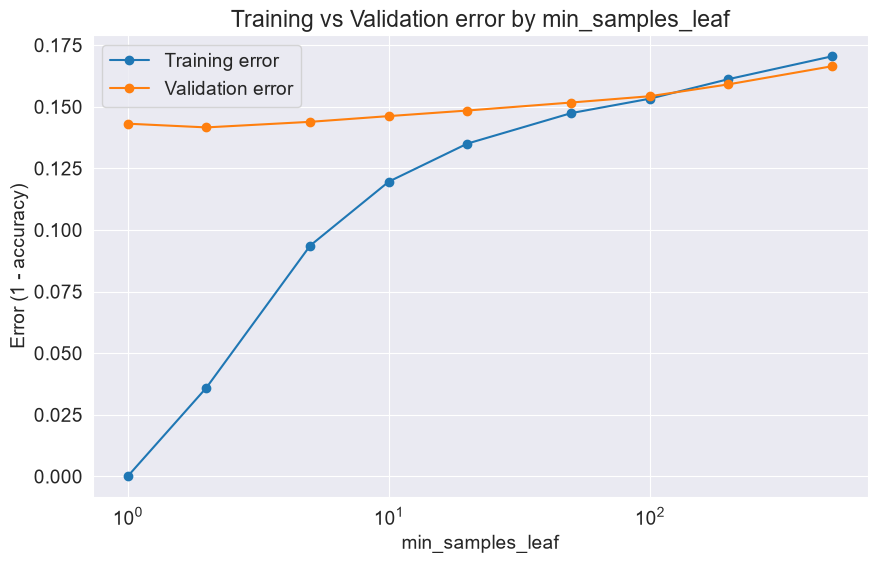

Optimal min_samples_leaf: 2


In [89]:
leaf_range = [1, 2, 5, 10, 20, 50, 100, 200, 500]
train_errors_leaf2 = []
val_errors_leaf2 = []

for l in leaf_range:
    model = RandomForestClassifier(random_state=42, n_jobs=-1, min_samples_leaf=l)
    model.fit(X_train, train_targets)
    train_acc = model.score(X_train, train_targets)
    val_acc = model.score(X_val, val_targets)
    train_errors_leaf2.append(1 - train_acc)
    val_errors_leaf2.append(1 - val_acc)

plt.figure(figsize=(10, 6))
plt.plot(leaf_range, train_errors_leaf2, 'o-', label='Training error')
plt.plot(leaf_range, val_errors_leaf2, 'o-', label='Validation error')
plt.xlabel('min_samples_leaf')
plt.ylabel('Error (1 - accuracy)')
plt.title('Training vs Validation error by min_samples_leaf')
plt.xscale('log')
plt.legend()
plt.grid(True)
plt.show()

best_leaf_idx = val_errors_leaf2.index(min(val_errors_leaf2))
print("Optimal min_samples_leaf:", leaf_range[best_leaf_idx])

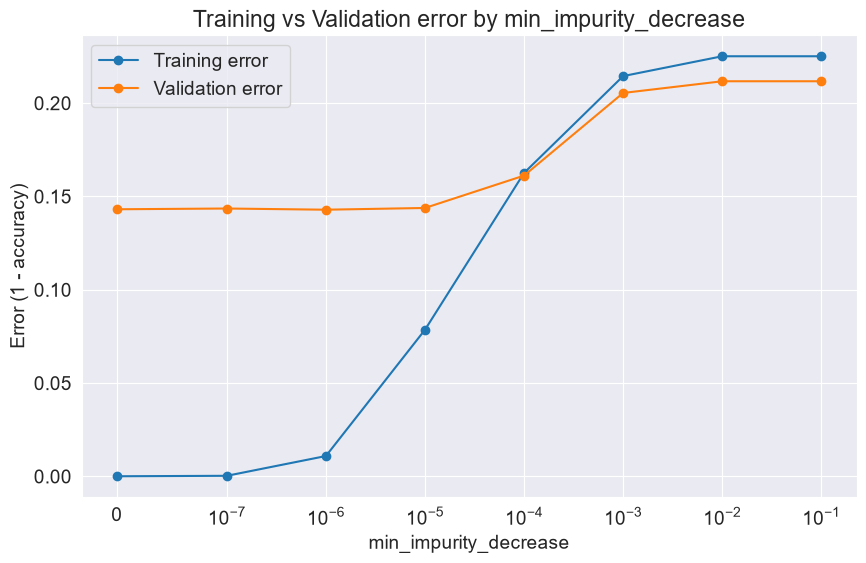

Optimal min_impurity_decrease: 1e-06


In [90]:
import matplotlib.pyplot as plt

impurity_range = [0, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
train_errors_imp = []
val_errors_imp = []

for m in impurity_range:
    model = RandomForestClassifier(random_state=42, n_jobs=-1, min_impurity_decrease=m)
    model.fit(X_train, train_targets)
    train_acc = model.score(X_train, train_targets)
    val_acc = model.score(X_val, val_targets)
    train_errors_imp.append(1 - train_acc)
    val_errors_imp.append(1 - val_acc)

plt.figure(figsize=(10, 6))
plt.plot(impurity_range, train_errors_imp, 'o-', label='Training error')
plt.plot(impurity_range, val_errors_imp, 'o-', label='Validation error')
plt.xlabel('min_impurity_decrease')
plt.ylabel('Error (1 - accuracy)')
plt.title('Training vs Validation error by min_impurity_decrease')
plt.xscale('symlog', linthresh=1e-7)  # symlog handles the 0 value, log scale for the rest
plt.legend()
plt.grid(True)
plt.show()

best_imp_idx = val_errors_imp.index(min(val_errors_imp))
print("Optimal min_impurity_decrease:", impurity_range[best_imp_idx])

In [ ]:
#kwargs :   is a Python feature that lets a function accept any number of keyword arguments, without you having to name them all in advance.
def test_params(**kwargs):
    model = RandomForestClassifier(random_state=42, n_jobs=-1, **kwargs)
    model.fit(X_train, train_targets)
    train_acc = model.score(X_train, train_targets)
    val_acc = model.score(X_val, val_targets)
    return train_acc, val_acc

In [103]:
test_params(bootstrap=False)

(0.9999797955307714, 0.8579885090824676)

In [105]:
test_params(max_samples=0.9)

(0.9997878530730998, 0.8579885090824676)

In [106]:
test_params(class_weight='balanced')
test_params(class_weight={'No': 1, 'Yes': 2})

(0.9999292843576999, 0.8583947536416923)

In [107]:
from sklearn.metrics import classification_report, f1_score

# First, check the actual class distribution to understand the imbalance
print(train_targets.value_counts())
print()

# Try a range of class_weight options
weight_options = [
    None,
    'balanced',
    {'No': 1, 'Yes': 2},
    {'No': 1, 'Yes': 3},
    {'No': 1, 'Yes': 5},
    {'No': 1, 'Yes': 10},
]

results = []
for w in weight_options:
    model = RandomForestClassifier(random_state=42, n_jobs=-1, class_weight=w)
    model.fit(X_train, train_targets)
    train_acc = model.score(X_train, train_targets)
    val_acc = model.score(X_val, val_targets)
    val_preds = model.predict(X_val)
    f1 = f1_score(val_targets, val_preds, pos_label='Yes')  # F1 for the minority class
    results.append((w, train_acc, val_acc, f1))
    print(f"class_weight={str(w):25s} | train_acc={train_acc:.4f} | val_acc={val_acc:.4f} | F1(Yes)={f1:.4f}")

RainTomorrow
No     76705
Yes    22283
Name: count, dtype: int64

class_weight=None                      | train_acc=0.9999 | val_acc=0.8569 | F1(Yes)=0.5747
class_weight=balanced                  | train_acc=0.9987 | val_acc=0.8527 | F1(Yes)=0.6370
class_weight={'No': 1, 'Yes': 2}       | train_acc=0.9999 | val_acc=0.8584 | F1(Yes)=0.6188
class_weight={'No': 1, 'Yes': 3}       | train_acc=0.9994 | val_acc=0.8543 | F1(Yes)=0.6327
class_weight={'No': 1, 'Yes': 5}       | train_acc=0.9929 | val_acc=0.8454 | F1(Yes)=0.6406
class_weight={'No': 1, 'Yes': 10}      | train_acc=0.9480 | val_acc=0.8201 | F1(Yes)=0.6372


In [108]:
# put together
model = RandomForestClassifier(n_jobs=-1, 
                               random_state=42, 
                               n_estimators=500,
                               max_features=7,
                               max_depth=30, 
                               class_weight={'No': 1, 'Yes': 1.5})
model.fit(X_train, train_targets)
model.score(X_train, train_targets), model.score(X_val, val_targets)
base_accs

(0.9999494888269285, 0.8568858452788579)

In [ ]:
model.score(X_test, test_targets)


0.8460768460768461